# Домашнее задание: SFT для function calling

Qwen2.5-0.5B-Instruct умеет вызывать функции в формате `<tool_call>`, но наши пять функций умного дома видит
впервые и обращается с ними вольно. Дообучим её целиком (все веса) на диалогах с умным домом
и в конце посмотрим, как она управляет симулятором.

| Блок | Баллы |
|---|---|
| 1. До обучения: генерация через chat template | 1 |
| 2. Данные: разбор примера и роль каждого сообщения | 2 |
| 3. Маска loss: теги `{% generation %}` в шаблоне | 2 |
| 4. Обучение | 3 |
| 5. Оценка на тест-сете (дано) | 0 |
| 6. Агентный цикл | 2 |

Дано и менять не нужно: `smart_home.py` (симулятор и схемы пяти функций), `chat_ui.py` (чат),
`data/` с `train.jsonl`, `validation.jsonl` и `test_cases.jsonl`.
Ячейки для заполнения помечены `для реализации`.

## 0. Окружение

Берём Instruct-модель: формат `<tool_call>` и токен конца реплики `<|im_end|>` она уже знает,
учить будем поведению с конкретными функциями.

In [1]:
# Окружение из requirements.txt. Используется только GPU 0.
# torch ставим именно с индекса cu126: колесо с PyPI по умолчанию собрано под CUDA 13 и требует драйвер >= 580.
# %pip install torch==2.8.0 --index-url https://download.pytorch.org/whl/cu126
# %pip install transformers==4.56.1 trl==0.23.1 datasets==3.6.0 accelerate==1.6.0 ipywidgets==8.1.9 matplotlib==3.10.1 pandas==2.2.3
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["HF_HUB_OFFLINE"] = "1"  # Используется модель из серверного кэша.

import gc
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

from chat_ui import launch_chat
from smart_home import BASELINE_PROMPTS, SMART_HOME_TOOLS, SYSTEM_PROMPT, SmartHome

SEED = 42
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
OUTPUT_DIR = Path("outputs/full_sft")
MAX_LENGTH = 2048

set_seed(SEED)
assert torch.cuda.is_available(), "Нужен GPU kernel"
assert torch.cuda.device_count() == 1, "Перезапустите kernel с CUDA_VISIBLE_DEVICES=0"
print("GPU 0:", torch.cuda.get_device_name(0))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 200)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, local_files_only=True)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.bfloat16, local_files_only=True).to("cuda")

GPU 0: NVIDIA A100-SXM4-80GB


## 1. До обучения · 1 балл

Функция для модели — это JSON Schema: имя, описание, аргументы с типами и ограничениями.
Схемы передаются в `apply_chat_template` параметром `tools`: шаблон вставит их в system-реплику
и объяснит модели формат ответа `<tool_call>`. Посмотрим, что именно получает модель на вход.

In [2]:
print(json.dumps(SMART_HOME_TOOLS[0], ensure_ascii=False, indent=2))
print("=" * 80)
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": "Turn on the kitchen light."},
]
print(tokenizer.apply_chat_template(messages, tools=SMART_HOME_TOOLS, tokenize=False, add_generation_prompt=True))

{
  "type": "function",
  "function": {
    "name": "turn_light",
    "description": "Switch a room light on or off. Ask for the room if unknown.",
    "parameters": {
      "type": "object",
      "properties": {
        "room": {
          "type": "string",
          "enum": [
            "kitchen",
            "bedroom",
            "living_room"
          ]
        },
        "state": {
          "type": "string",
          "enum": [
            "on",
            "off"
          ]
        }
      },
      "required": [
        "room",
        "state"
      ],
      "additionalProperties": false
    }
  }
}
<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"n

**Задание (1 балл).** Напишите `generate`: сообщения и схемы функций проходят через `apply_chat_template`
с `add_generation_prompt=True`, декодирование жадное, стоп на `<|im_end|>` (это `eos_token` токенизатора).
Верните только новые токены, без спецтокенов. Эта функция используется во всех следующих блоках.

In [3]:
@torch.inference_mode()
def generate(model, tokenizer, messages, tools, max_new_tokens=256):
    model.eval()
    inputs = tokenizer.apply_chat_template(
        messages, tools=tools, add_generation_prompt=True,
        tokenize=True, return_dict=True, return_tensors="pt",
    ).to(model.device)
    end_id = tokenizer.convert_tokens_to_ids("<|im_end|>")
    assert end_id == tokenizer.eos_token_id
    output = model.generate(
        **inputs, max_new_tokens=max_new_tokens, do_sample=False,
        eos_token_id=end_id,
        pad_token_id=tokenizer.pad_token_id if tokenizer.pad_token_id is not None else end_id,
    )
    return tokenizer.decode(
        output[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True,
    )


def answer(model, tokenizer, prompt):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}]
    return generate(model, tokenizer, messages, SMART_HOME_TOOLS)

Формат модель знает, поэтому простые запросы отработает правильно. Смотрите на сложные: «Open the garage» —
модель подставляет в `turn_light` комнату `garage`, которой нет в схеме; «Turn off all lights» — придумывает
`room: "all"` вместо трёх вызовов; «Turn on the light» — выбирает комнату сама вместо уточняющего вопроса.
Запомним её ответы на десять запросов, после обучения сравним.

In [4]:
comparison = pd.DataFrame({"prompt": BASELINE_PROMPTS})
comparison["base"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


,prompt,base
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>"
7,Hello!,How can I help you today?
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>"
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>"


## 2. Данные · 2 балла

Чтобы модель вызывала функции, покажем ей диалоги, где это делается правильно.
Одна строка JSONL — один диалог: `messages` и `tools`. Вызов функции — поле `tool_calls`
у реплики assistant, результат функции — отдельное сообщение с ролью `tool`.

In [5]:
def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


def show_dialog(messages):
    for message in messages:
        print(f"[{message['role']}] {message.get('content', '')}")
        for call in message.get("tool_calls") or []:
            arguments = json.dumps(call["function"]["arguments"], ensure_ascii=False)
            print(f"    -> {call['function']['name']}({arguments})")


train_rows = read_jsonl("data/train.jsonl")
validation_rows = read_jsonl("data/validation.jsonl")
print(f"train: {len(train_rows)}, validation: {len(validation_rows)}\n")

example = next(row for row in train_rows if any(m.get("tool_calls") for m in row["messages"]))
show_dialog(example["messages"])

train: 831, validation: 91

[system] You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.
[user] Сделай в гостиной 40 градусов, гости мерзнут
[assistant] Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?
[user] Хорошо, тогда максимум
[assistant] 
    -> set_temperature({"room": "living_room", "value": 30})
[tool] {"room": "living_room", "light": "off", "temperature": 30}
[assistant] Готово, в гостиной теперь 30 градусов.


В данных четыре типа диалогов. Примеры без вызова — не балласт: это единственное место, где модель видит,
что на неподдерживаемый запрос («открой гараж», «какая погода») нужно ответить отказом, а не подобрать
ближайшую функцию.

In [6]:
def scenario_type(row):
    calls_per_message = [len(m.get("tool_calls") or []) for m in row["messages"]]
    if sum(calls_per_message) == 0:
        return "no_call"
    if sum(n > 0 for n in calls_per_message) > 1:
        return "multi_turn"
    return "parallel_calls" if max(calls_per_message) > 1 else "single_call"


pd.DataFrame({
    "train": pd.Series([scenario_type(row) for row in train_rows]).value_counts(),
    "validation": pd.Series([scenario_type(row) for row in validation_rows]).value_counts(),
})

,train,validation
multi_turn,219,22
no_call,144,16
parallel_calls,145,15
single_call,323,38


Тот же диалог после шаблона — ровно такой текст модель увидит на обучении. `tool_calls` стали блоками
`<tool_call>` внутри реплики assistant, а результат функции — блоком `<tool_response>` внутри реплики
**user**: для модели это входящая информация, как и вопрос пользователя.

In [7]:
print(tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False))

<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "turn_light", "description": "Switch a room light on or off. Ask for the room if unknown.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "bedroom", "living_room"]}, "state": {"type": "string", "enum": ["on", "off"]}}, "required": ["room", "state"], "additionalProperties": false}}}
{"type": "function", "function": {"name": "set_temperature", "description": "Set an absolute room temperature in Celsius. For relative changes, obtain the current temperature first.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "

### Разбор данных

Результат функции это внешняя информация, а не ответ модели. Поэтому шаблон помещает его в user, хотя в исходных данных роль называется tool. Модель должна прочитать этот результат и уже потом ответить. Если считать loss ещё и по `<tool_response>`, она будет учиться придумывать результат выполнения. Например писать что свет включён хотя функция вообще не сработала.

В train есть четыре типа диалогов:

- `single_call` — 323 примера. Учат выбрать функцию и передать аргументы. Без них будет не хватать простых примеров как вообще делается вызов.
- `parallel_calls` — 145. Учат выдавать несколько вызовов за один ответ, например выключить свет во всех трёх комнатах. Без них модель может сделать только часть запроса или придумать комнату `all`.
- `multi_turn` — 219. Учат использовать историю и результаты функций, уточнять запрос и делать действия по очереди. Без них будет сложно сначала узнать температуру, потом увеличить её или понять «ещё на два градуса».
- `no_call` — 144. Учат отвечать без функций, отказывать в неподдерживаемых действиях и спрашивать недостающие аргументы. Без них модель начнёт вызывать что-нибудь даже когда это не нужно.

## 3. Маска loss · 2 балла

В тексте выше модель должна учиться только своим репликам: тексту, `<tool_call>` и `<|im_end|>`.
Запрос пользователя и результат функции она читает, но не предсказывает — у этих токенов label `-100`.
За это в TRL отвечает `assistant_only_loss=True`, а маску он строит по тегам
`{% generation %}…{% endgeneration %}` в chat template. В нативном шаблоне Qwen их нет.

In [8]:
NATIVE_TEMPLATE = tokenizer.chat_template
print(NATIVE_TEMPLATE)

{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nYou are Qwen, created by Alibaba C

**Задание (2 балла).** Оберните в `{% generation %}…{% endgeneration %}` вывод реплик assistant — и текст,
и `tool_calls` — и присвойте результат в `tokenizer.chat_template`. Текст, который рендерит шаблон,
меняться не должен: теги влияют только на маску. Ячейка после задания проверит и то, и другое,
и напечатает токены, по которым будет считаться loss.

In [9]:
# Меняется только маска, строки исходного шаблона остаются теми же.
TRAIN_TEMPLATE = NATIVE_TEMPLATE
plain_outputs = [
    r"{{- '<|im_start|>' + message.role + '\n' + message.content + '<|im_end|>' + '\n' }}",
    r"{{- '<|im_start|>' + message.role + '\n' + message.content + '<|im_end|>\n' }}",
]
plain_output = next((part for part in plain_outputs if part in TRAIN_TEMPLATE), None)
assert plain_output is not None, "Неожиданный формат исходного Qwen chat template"
assert TRAIN_TEMPLATE.count(plain_output) == 1
TRAIN_TEMPLATE = TRAIN_TEMPLATE.replace(
    plain_output,
    "{%- if message.role == 'assistant' %}"
    r"{{- '<|im_start|>assistant\n' }}"
    r"{% generation %}{{- message.content + '<|im_end|>\n' }}{% endgeneration %}"
    "{%- else %}" + plain_output + "{%- endif %}",
    1,
)

# Отдельная ветка assistant с tool_calls.
assistant_header = "{{- '<|im_start|>' + message.role }}"
tool_branch = '{%- elif message.role == "tool" %}'
assert TRAIN_TEMPLATE.count(assistant_header) == 1
start = TRAIN_TEMPLATE.index(assistant_header) + len(assistant_header)
end = TRAIN_TEMPLATE.index(tool_branch, start)
body = TRAIN_TEMPLATE[start:end]
assistant_end = r"{{- '<|im_end|>\n' }}"
assert body.count(assistant_end) == 1
body = "{% generation %}" + body.replace(
    assistant_end, assistant_end + "{% endgeneration %}", 1,
)
TRAIN_TEMPLATE = TRAIN_TEMPLATE[:start] + body + TRAIN_TEMPLATE[end:]
tokenizer.chat_template = TRAIN_TEMPLATE

# Проверяем неизменность рендера на всех предоставленных диалогах.
for row in train_rows + validation_rows:
    for add_prompt in (False, True):
        options = dict(tools=row["tools"], tokenize=False, add_generation_prompt=add_prompt)
        assert tokenizer.apply_chat_template(row["messages"], **options) == tokenizer.apply_chat_template(
            row["messages"], chat_template=NATIVE_TEMPLATE, **options,
        )
print("Текст шаблона не изменился на train и validation.")

Текст шаблона не изменился на train и validation.


In [10]:
rendered = tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False)
assert rendered == tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"], tokenize=False, chat_template=NATIVE_TEMPLATE
), "Теги изменили текст шаблона"

encoded = tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"],
    tokenize=True, return_dict=True, return_assistant_tokens_mask=True,
)
trained = tokenizer.decode([token for token, flag in zip(encoded["input_ids"], encoded["assistant_masks"]) if flag])
assert "<tool_call>" in trained and "<|im_end|>" in trained, "Реплики assistant не попали в маску"
assert "<tools>" not in trained and "<tool_response>" not in trained, "В маске лишние токены"
print(f"учим {sum(encoded['assistant_masks'])} из {len(encoded['input_ids'])} токенов:\n")
print(trained)

учим 89 из 764 токенов:

Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?<|im_end|>

<tool_call>
{"name": "set_temperature", "arguments": {"room": "living_room", "value": 30}}
</tool_call><|im_end|>
Готово, в гостиной теперь 30 градусов.<|im_end|>



## 4. Обучение · 3 балла

Данные и маска готовы. `SFTTrainer` сам применит шаблон к `messages` и `tools`, а `assistant_only_loss=True`
возьмёт маску из ваших тегов. Обучаем все веса модели.

In [11]:
def drop_nulls(value):
    if isinstance(value, dict):
        return {key: drop_nulls(item) for key, item in value.items() if item is not None}
    if isinstance(value, list):
        return [drop_nulls(item) for item in value]
    return value


def to_dataset(rows):
    # Arrow приводит схемы всех функций к общей структуре и дописывает отсутствующим полям null,
    # из-за чего в JSON Schema появилось бы "enum": null. Убираем null при чтении примеров.
    dataset = Dataset.from_list([{"messages": row["messages"], "tools": row["tools"]} for row in rows])
    return dataset.with_transform(lambda batch: {key: [drop_nulls(item) for item in items] for key, items in batch.items()})


train_dataset = to_dataset(train_rows)
validation_dataset = to_dataset(validation_rows)

**Задание (3 балла).** Заполните `SFTConfig`, создайте `SFTTrainer`, обучите модель и сохраните её в `OUTPUT_DIR`
(`trainer.save_model()` сохранит и токенизатор с вашим шаблоном). Ориентир: 3 эпохи на 0.5B — пара минут на A100.

In [12]:
config = SFTConfig(
    output_dir=str(OUTPUT_DIR),
    num_train_epochs=3,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    per_device_eval_batch_size=4,
    learning_rate=5e-5,
    lr_scheduler_type="cosine",
    warmup_ratio=0.05,
    weight_decay=0.01,
    max_length=MAX_LENGTH,
    assistant_only_loss=True,
    bf16=True,
    optim="adamw_torch_fused",
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    packing=False,
)
assert all(parameter.requires_grad for parameter in model.parameters())
trainer = SFTTrainer(
    model=model,
    args=config,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    processing_class=tokenizer,
)

# Проверяем labels не только на уровне шаблона, но и после collator.
sample = trainer.train_dataset[0]
batch = trainer.data_collator([sample])
mask = torch.tensor(sample["assistant_masks"], dtype=torch.bool)
length = len(sample["input_ids"])
labels = batch["labels"][0, :length]
assert (labels[~mask] == -100).all()
assert torch.equal(labels[mask], batch["input_ids"][0, :length][mask])
assert mask.any()
print("Маска labels проверена, все веса обучаются.")

trainer.train()
trainer.save_model(str(OUTPUT_DIR))
tokenizer.save_pretrained(OUTPUT_DIR)
assert tokenizer.chat_template == TRAIN_TEMPLATE
print("Модель и токенизатор сохранены:", OUTPUT_DIR)

Tokenizing train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Маска labels проверена, все веса обучаются.


Epoch,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
1,0.194400,0.299809,0.882784,631625.000000,0.920589
2,0.106600,0.275736,0.736228,1263250.000000,0.930491
3,0.058100,0.280737,0.671240,1894875.000000,0.931910


Модель и токенизатор сохранены: outputs/full_sft


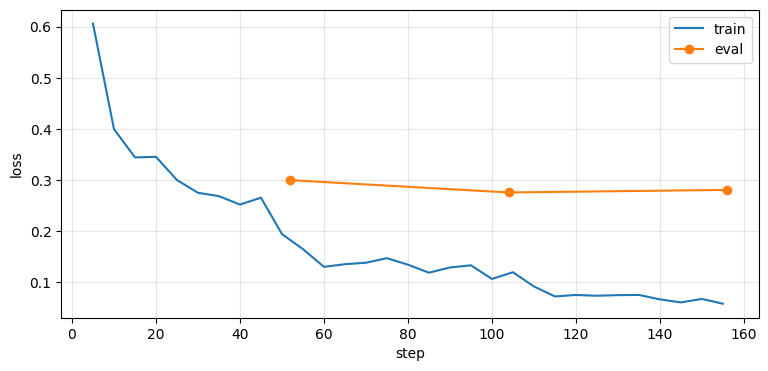

In [13]:
history = pd.DataFrame(trainer.state.log_history)
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_loss"])

plt.figure(figsize=(9, 4))
plt.plot(train_log["step"], train_log["loss"], label="train")
plt.plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="eval")
plt.xlabel("step")
plt.ylabel("loss")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### Про loss

Loss считается только по ответам assistant, включая вызовы и конец реплики. Пользователь и tool-результаты остаются контекстом но их labels равны -100. Без маски часть обучения тратилась бы на предсказание чужих сообщений. Даже низкий val loss ещё не значит что все функции вызываются правильно, поэтому отдельно проверяются имена функций и аргументы на тест-сете.

В конце первой эпохи train loss был 0.1944, в конце третьей — 0.0581. Val loss по эпохам: 0.2998 → 0.2757 → 0.2807. На последней эпохе он немного вырос хотя train продолжил падать. Похоже уже начинает появляться переобучение, поэтому дальше учить без проверки валидации смысла мало.

## 5. Оценка на тест-сете

Eval loss показывает, насколько хорошо модель предсказывает ответы в валидационных диалогах, но не отвечает
на главный вопрос: вызывает ли она нужные функции. Проверим напрямую на `data/test_cases.jsonl`: 60 запросов к умному дому
(40 EN, 20 RU) с ожидаемыми вызовами.
- `tool_set_accuracy` — совпал набор вызванных функций (для запросов без вызова — модель ничего не вызвала);
- `exact_match` — совпали ещё и аргументы.

Битый `<tool_call>` или невалидный JSON — ошибка.

In [14]:
TOOL_CALL_PATTERN = re.compile(r"<tool_call>\s*(.*?)\s*</tool_call>", re.DOTALL)


def parse_tool_calls(text):
    """Вызовы {name, arguments} из ответа модели. None — формат нарушен."""
    blocks = TOOL_CALL_PATTERN.findall(text)
    if len(blocks) != text.count("<tool_call>"):
        return None
    try:
        calls = [json.loads(block) for block in blocks]
    except ValueError:
        return None
    if not all(isinstance(call, dict) and isinstance(call.get("name"), str) and isinstance(call.get("arguments"), dict) for call in calls):
        return None
    return [{"name": call["name"], "arguments": call["arguments"]} for call in calls]


ARGUMENT_DEFAULTS = {
    tool["function"]["name"]: {name: spec["default"] for name, spec in tool["function"]["parameters"]["properties"].items() if "default" in spec}
    for tool in SMART_HOME_TOOLS
}


def canonical(calls):
    """Вызовы как отсортированные строки; пропущенный аргумент со значением по умолчанию (quantity=1) равен явному."""
    filled = [{"name": c["name"], "arguments": {**ARGUMENT_DEFAULTS.get(c["name"], {}), **c["arguments"]}} for c in calls]
    return sorted(json.dumps(c, sort_keys=True) for c in filled)


def evaluate(model, tokenizer, cases):
    rows = []
    for case in cases:
        messages = case["messages"]
        if messages[0]["role"] != "system":
            messages = [{"role": "system", "content": SYSTEM_PROMPT}, *messages]
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        tools_ok = calls is not None and {call["name"] for call in calls} == set(case["expected_tools"])
        rows.append({
            "id": case["id"], "lang": case["lang"], "output": output,
            "tools_ok": tools_ok,
            "args_ok": tools_ok and canonical(calls) == canonical(case["expected_calls"]),
        })
    return pd.DataFrame(rows)


def summarize(results):
    return results.groupby("lang").agg(tool_set_accuracy=("tools_ok", "mean"), exact_match=("args_ok", "mean"))

In [15]:
del trainer
gc.collect()
torch.cuda.empty_cache()
model.eval()  # trainer мог оставить модель в train-режиме

cases = read_jsonl("data/test_cases.jsonl")
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.bfloat16, local_files_only=True).to("cuda")
scores = pd.concat([
    summarize(evaluate(base_model, tokenizer, cases)).assign(model="base"),
    summarize(evaluate(model, tokenizer, cases)).assign(model="sft"),
]).reset_index()[["model", "lang", "tool_set_accuracy", "exact_match"]]
del base_model
gc.collect()
torch.cuda.empty_cache()

scores.to_csv("outputs/eval_results.csv", index=False)
display(scores)

,model,lang,tool_set_accuracy,exact_match
0,base,en,0.75,0.550
1,base,ru,0.75,0.200
2,sft,en,1.00,0.975
3,sft,ru,1.00,1.000


Те же десять запросов: base-модель и обученная.

In [3]:
pd.set_option("display.max_colwidth", None)
comparison["after_sft"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)

,prompt,base,after_sft
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>","<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>","<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>","<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""cartons of milk"", ""quantity"": 2}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>","<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool_call>"
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""off""}}\n</tool_call>"
7,Hello!,How can I help you today?,"Hi! I can control lights and temperature in the kitchen, bedroom and living room, manage your shopping list and set timers. What would you like?"
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>","I can't control the garage. I can handle lights, temperature, your shopping list and timers."
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>","Which room: kitchen, bedroom or living room?"


### Что получилось после SFT

Обучение шло на A100 80GB, GPU 0: 3 эпохи, 156 шагов, batch 4 и accumulation 4, LR 5e-5, cosine и warmup 5%, BF16, seed 42. Обучались все веса, без адаптеров. Максимальная длина — 2048. Вместе с подготовкой trainer и сохранением весов эта ячейка заняла около 127 секунд.

На 60 тестовых запросах выбор функций улучшился с 45/60 до 60/60, exact match с 26/60 до 59/60. То есть **75% → 100%** и **43.3% → 98.3%**. На английском exact match вырос с 55% до 97.5%, на русском с 20% до 100%. В одном английском примере аргументы всё ещё не совпали с эталоном. Так что до идеального результата немного не хватило.

На десяти контрольных запросах простые вызовы работали и до обучения. Зато теперь для всех ламп получаются три вызова вместо комнаты `all`, на гараж идёт отказ, а если комната не указана модель спрашивает какую. Название товара тоже изменилось: `milk` стало `cartons of milk`. Это показывает что текстовые аргументы могут зависеть от формулировки, даже когда сама функция выбрана верно.

В целом SFT помог не только с JSON, но и с тем когда вообще не надо вызывать функцию. Но тест маленький, особенно русская часть — всего 20 запросов. Поэтому 100% здесь ещё не значит что модель справится с любым запросом.


## 6. Агентный цикл · 2 балла

Модель печатает `<tool_call>`, но сама ничего не выполняет. Чтобы свет действительно включился,
нужен цикл: ответ модели → парсим вызовы → выполняем в симуляторе → результаты добавляем в историю
сообщениями `tool` → снова спрашиваем модель. Останавливаемся, когда модель ответила без вызовов.
`max_steps` защищает от бесконечных вызовов.

**Задание (2 балла).** Напишите `run_agent`: функция дописывает в `messages` реплики assistant
(с `tool_calls` в формате данных) и сообщения `tool`, пока модель не ответит текстом или не кончатся шаги.
Проверка — пять сценариев ниже: один вызов, два вызова за ход, относительное изменение температуры
(сначала нужно прочитать состояние), ответ без вызова и неподдерживаемый запрос. Оцениваем цикл, а не модель:
каждый вызов выполнен, результат попал в историю, состояние дома соответствует сделанным вызовам,
на неподдерживаемом запросе вызовов нет.

In [17]:
def run_agent(model, tokenizer, home, messages, max_steps=4):
    for _ in range(max_steps):
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        if calls is None:
            # Неполный JSON не выполняется и не маскируется под успех.
            messages.append({"role": "assistant", "content": output})
            return messages
        text = TOOL_CALL_PATTERN.sub("", output).strip()
        if not calls:
            messages.append({"role": "assistant", "content": text})
            return messages
        messages.append({
            "role": "assistant", "content": text,
            "tool_calls": [
                {"type": "function", "function": call} for call in calls
            ],
        })
        for call in calls:
            result = home.call(call["name"], call["arguments"])
            messages.append({
                "role": "tool", "name": call["name"],
                "content": json.dumps(result, ensure_ascii=False),
            })
    messages.append({
        "role": "assistant", "content": "Tool step limit reached; stopping.",
    })
    return messages

In [18]:
scenarios = [
    ["Turn on the kitchen light."],
    ["Turn on the kitchen light and set it to 23 degrees."],
    ["Make it two degrees warmer in the bedroom.", "Two more degrees."],
    ["Thanks!"],
    ["Open the garage."],
]
agent_results = []
for prompts in scenarios:
    home = SmartHome()
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    for prompt in prompts:
        messages.append({"role": "user", "content": prompt})
        run_agent(model, tokenizer, home, messages)
    print("=" * 80)
    show_dialog(messages[1:])
    print(f"дом: {json.dumps(home.snapshot(), ensure_ascii=False)}")
    replay = SmartHome()
    pending = []
    for message in messages:
        if message["role"] == "assistant" and message.get("tool_calls"):
            assert not pending
            pending = [call["function"] for call in message["tool_calls"]]
        elif message["role"] == "tool":
            assert pending
            call = pending.pop(0)
            assert message["name"] == call["name"]
            assert json.loads(message["content"]) == replay.call(call["name"], call["arguments"])
    assert not pending
    assert replay.snapshot() == home.snapshot()
    if prompts in (["Thanks!"], ["Open the garage."]):
        assert not any(message.get("tool_calls") for message in messages)
    agent_results.append({"prompts": prompts, "messages": messages, "state": home.snapshot()})
print("Проверки пяти сценариев пройдены.")

[user] Turn on the kitchen light.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[assistant] The kitchen light is on.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Turn on the kitchen light and set it to 23 degrees.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
    -> set_temperature({"room": "kitchen", "value": 23})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[tool] {"room": "kitchen", "light": "on", "temperature": 23}
[assistant] The kitchen light is on and it's set to 23 degrees.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 23}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Make it two degrees warmer in the bedroom.
[assistant] 
    -> get_room_state({"room": "bedroom"})
[tool] {"room": "bedroom", "light": "off", "temperature": 21}
[assistant] 
    -> set_temperature({"room": "bedroom", "value": 23})
[tool] {"room": "bedroom", "light": "off", "temperature": 23}
[assistant] The bedroom is now at 23 degrees.
[user] Two more degrees.
[assistant] 
    -> set_temperature({"room": "bedroom", "value": 25})
[tool] {"room": "bedroom", "light": "off", "temperature": 25}
[assistant] Done, the bedroom is now at 25 degrees.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 25}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Thanks!
[assistant] You're welcome! Just ask if you need anything else.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Open the garage.
[assistant] I can't control the garage. I can handle lights, temperature, your shopping list and timers.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
Проверки пяти сценариев пройдены.


### Проверка агента

Все пять сценариев прошли. В первом включился свет кухни, во втором ещё установилась температура 23. Для относительного изменения сначала прочиталось состояние спальни, потом температура изменилась 21 → 23 → 25. На благодарность и просьбу открыть гараж вызовов не было. Проверка повторно выполнила записанные вызовы в отдельном симуляторе: результаты и итоговое состояние совпали.


Тот же `run_agent` в чате: слева диалог и вызовы функций, справа состояние дома.
Попробуйте `Turn off all lights.`, `Add milk to my shopping list.`, `Set a 5-minute timer labeled tea.`

In [19]:
launch_chat(model, tokenizer, SmartHome(), run_agent)